In [3]:
#Cargamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as special
from scipy.optimize import curve_fit
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [6]:
#Cargar archivo csv
df= pd.read_csv("/content/bp_limpio.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 15 columns):
 #   Column                                      Non-Null Count  Dtype 
---  ------                                      --------------  ----- 
 0   Fecha                                       207 non-null    object
 1   Nombre Cliente                              207 non-null    object
 2   Asesor                                      207 non-null    object
 3   Esatus Lead                                 207 non-null    object
 4   PDM                                         207 non-null    bool  
 5   SDC                                         207 non-null    bool  
 6   Venta                                       207 non-null    bool  
 7   Inter Gerente                               207 non-null    bool  
 8   ¿Por que no hubo prueba de manejo?          207 non-null    object
 9   ¿Por que no hubo Solicitud de credito?      207 non-null    object
 10  ¿Por que no hubo intervenc

,Fecha,Nombre Cliente,Asesor,Esatus Lead,PDM,SDC,Venta,Inter Gerente,¿Por que no hubo prueba de manejo?,¿Por que no hubo Solicitud de credito?,¿Por que no hubo intervencion del Gerente?,¿Por que no hubo proceso wow?,¿Por que no se ha formalizado la compra?,5 porques clientes de piso,Comentarios
0,04/01/2025,Ubaldo Cruz Hernandez,Aurelio Torres,Activo,True,False,False,True,Sí hubo prueba de manejo.,"El cliente acudió con una prima, para ella ser...","Sí hubo interacción del gerente, los cliente s...","Sí hubo proceso wow, se recibío al cliente con...",Tiempo de compra hasta el próximo año.,El cliente llego ocasionalmente antes de llega...,Sin comentarios
1,04/01/2025,Olivia Cabello,Pedro González,Activo,False,False,False,True,La clienta piensa acudir con sus hijos para ha...,Es una decisión que prefiere tomar con sus hijos.,Sí hubo intervención del Gerente. Converse con...,"Sí hubo un proceso wow, además de la interacci...",Sin comentarios,Clienta viene buscando opciones para ella y su...,Sin comentarios
2,04/02/2025,Ana Laura Espinoza,Mauricio Vázquez,Activo,True,True,True,True,"Sí hubo prueba de manejo por la tarde, ya que ...",Ingresa SDC con el perfil de ella y el de su e...,Sí hubo intervención del gerente en las dos vi...,Calificación 5,No se formalizo la venta ya que fue rechazado ...,El cliente visito la agencia porque iba pasand...,Sin comentarios
3,04/02/2025,Elvis Sanchez,Aurelio Torres,Activo,False,False,False,True,El cliente no quiso porque sabe que no se encu...,El cliente comenta que en este momento tiene c...,"Sí hubo intervención y me comento su estatus, ...",Calificación 5,Porque por el momento no cuenta con moviemient...,El Señor Elvis se encuentra evaluando diferent...,Sin comentarios
4,04/03/2025,Ariel Fernando López,Alan González,Activo,True,False,False,True,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,El cliente se encuentra en busqueda de renovar...,Sin comentarios


In [5]:
#Rellenamos nulos
df = df.bfill()
df = df.ffill()

In [7]:
#Verificar los valores sin repetirse de una columna
unico = np.unique(df['Esatus Lead'])
unico

array(['Activo', 'Activo ', 'Cerrado', 'Cerrado ', 'Finalizado',
       'Finalizado ', 'Sin datos', 'Venta', 'Venta ', 'venta'],
      dtype=object)

In [8]:
#Convertimos una variable categórica a dicotómica
df['Esatus Lead']= df['Esatus Lead'].replace(["Activo "], "Activo")
df['Esatus Lead']= df['Esatus Lead'].replace(["Cerrado", "Cerrado ", "Finalizado", "Finalizado ", "Sin datos", "Venta", "Venta ", "venta"], "No activo")
df['Esatus Lead']= df['Esatus Lead'].replace(["Activo", "No activo"], [1, 0])
df

/tmp/ipykernel_1716/1385066223.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Esatus Lead']= df['Esatus Lead'].replace(["Activo", "No activo"], [1, 0])


,Fecha,Nombre Cliente,Asesor,Esatus Lead,PDM,SDC,Venta,Inter Gerente,¿Por que no hubo prueba de manejo?,¿Por que no hubo Solicitud de credito?,¿Por que no hubo intervencion del Gerente?,¿Por que no hubo proceso wow?,¿Por que no se ha formalizado la compra?,5 porques clientes de piso,Comentarios
0,04/01/2025,Ubaldo Cruz Hernandez,Aurelio Torres,1,True,False,False,True,Sí hubo prueba de manejo.,"El cliente acudió con una prima, para ella ser...","Sí hubo interacción del gerente, los cliente s...","Sí hubo proceso wow, se recibío al cliente con...",Tiempo de compra hasta el próximo año.,El cliente llego ocasionalmente antes de llega...,Sin comentarios
1,04/01/2025,Olivia Cabello,Pedro González,1,False,False,False,True,La clienta piensa acudir con sus hijos para ha...,Es una decisión que prefiere tomar con sus hijos.,Sí hubo intervención del Gerente. Converse con...,"Sí hubo un proceso wow, además de la interacci...",Sin comentarios,Clienta viene buscando opciones para ella y su...,Sin comentarios
2,04/02/2025,Ana Laura Espinoza,Mauricio Vázquez,1,True,True,True,True,"Sí hubo prueba de manejo por la tarde, ya que ...",Ingresa SDC con el perfil de ella y el de su e...,Sí hubo intervención del gerente en las dos vi...,Calificación 5,No se formalizo la venta ya que fue rechazado ...,El cliente visito la agencia porque iba pasand...,Sin comentarios
3,04/02/2025,Elvis Sanchez,Aurelio Torres,1,False,False,False,True,El cliente no quiso porque sabe que no se encu...,El cliente comenta que en este momento tiene c...,"Sí hubo intervención y me comento su estatus, ...",Calificación 5,Porque por el momento no cuenta con moviemient...,El Señor Elvis se encuentra evaluando diferent...,Sin comentarios
4,04/03/2025,Ariel Fernando López,Alan González,1,True,False,False,True,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,El cliente se encuentra en busqueda de renovar...,Sin comentarios
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202,07/08/2025,Jose Luis Blaz,Pedro González,1,False,False,False,False,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin razones,Sin comentarios
203,07/08/2025,Erick Cruz,Mauricio Vázquez,1,False,False,False,False,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin razones,Sin comentarios
204,07/09/2025,David Moran,Aurelio Torres,1,False,False,False,False,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin razones,Sin comentarios
205,07/10/2025,Medeo Martínez Ferro,Pedro González,1,True,False,False,False,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin comentarios,Sin razones,Sin comentarios


In [14]:
#Analizar categorias de una columna
Categorias = df.groupby(['PDM'])['PDM'].count()
Categorias

,PDM
PDM,
False,132
True,75


In [16]:
#Declaramos las variables dependientes e independientes para la regresión Logística
Vars_Indep= df[['SDC', 'Inter Gerente', 'Esatus Lead', "Venta"]]
Var_Dep= df['PDM']

In [17]:
#Redefinimos las variables
X= Vars_Indep
y= Var_Dep

In [18]:
#Dividimos el conjunto de datos en la parte de entrenamiento y prueba:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state =None)

In [19]:
#Se escalan todos los datos
escalar = StandardScaler()

In [20]:
#Para realizar el escalamiento de las variables "X" tanto de entrenamiento como de prueba, utilizaremos fit_transform
X_train = escalar.fit_transform(X_train)
X_test = escalar.transform(X_test)

**Regresión logística sin balanceo**

In [21]:
#Definimos el algoritmo a utilizar
from sklearn.linear_model import LogisticRegression
algoritmo = LogisticRegression()

In [22]:
#Entrenamos el modelo
algoritmo.fit(X_train, y_train)

LogisticRegression()

In [23]:
#Realizamos una predicción
y_pred = algoritmo.predict(X_test)
y_pred

array([False,  True, False, False, False, False,  True, False, False,
        True, False, False, False, False,  True, False, False, False,
        True, False, False, False, False, False,  True, False, False,
       False, False, False, False, False,  True, False,  True, False,
       False,  True, False, False, False,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False])

In [24]:
#Verifico la matriz de Confusión
from sklearn.metrics import confusion_matrix
matriz = confusion_matrix(y_test, y_pred)
print('Matriz de Confusión:')
print(matriz)

Matriz de Confusión:
[[36  2]
 [17  8]]


**Métricas**

In [25]:
#Calculo la precisión del modelo
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred, average="binary", pos_label=True)
print('Precisión del modelo:')
print(precision)

Precisión del modelo:
0.8


In [28]:
#Calculo la exactitud del modelo
from sklearn.metrics import accuracy_score

exactitud = accuracy_score(y_test, y_pred)
print('Exactitud del modelo:')
print(exactitud)

Exactitud del modelo:
0.6984126984126984


In [29]:
#Calculo la sensibilidad del modelo
from sklearn.metrics import recall_score

sensibilidad = recall_score(y_test, y_pred, average="binary", pos_label=True)
print('Sensibilidad del modelo:')
print(sensibilidad)

Sensibilidad del modelo:
0.32


In [30]:
#Calculo el Puntaje F1 del modelo
from sklearn.metrics import f1_score

puntajef1 = f1_score(y_test, y_pred, average="binary", pos_label=True)
print('Puntaje F1 del modelo:')
print(puntajef1)

Puntaje F1 del modelo:
0.45714285714285713


**Sobremuestreo (oversampling)**

In [37]:
pip install imblearn

In [38]:
#Aplicamos la técnica de sobremuestreo (oversampling)
from imblearn.over_sampling import SMOTE

smote = SMOTE()
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

In [39]:
#Entrenamos el modelo sobremuestreado
algoritmo_Over_sampling = LogisticRegression()
algoritmo_Over_sampling.fit(X_resampled, y_resampled)

LogisticRegression()

In [40]:
#Realizamos una predicción
y_pred_over_sampling = algoritmo_Over_sampling.predict(X_test)
y_pred_over_sampling

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True, False,  True,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True, False,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False, False])

In [41]:
#Verifico la matriz de Confusión
matriz = confusion_matrix(y_test, y_pred_over_sampling)
print('Matriz de Confusión:')
print(matriz)

Matriz de Confusión:
[[ 6 32]
 [ 2 23]]


Métricas

In [42]:
#Calculo la precisión del modelo
precision = precision_score(y_test, y_pred_over_sampling, average="binary", pos_label=True)
print('Precisión del modelo:')
print(precision)

Precisión del modelo:
0.41818181818181815


In [43]:
#Calculo la exactitud del modelo
exactitud = accuracy_score(y_test, y_pred_over_sampling)
print('Exactitud del modelo:')
print(exactitud)

Exactitud del modelo:
0.4603174603174603


In [44]:
#Calculo la sensibilidad del modelo
sensibilidad = recall_score(y_test, y_pred_over_sampling, average="binary", pos_label=True)
print('Sensibilidad del modelo:')
print(sensibilidad)

Sensibilidad del modelo:
0.92


# **Heatmap de la matris de confusión con oversampling**

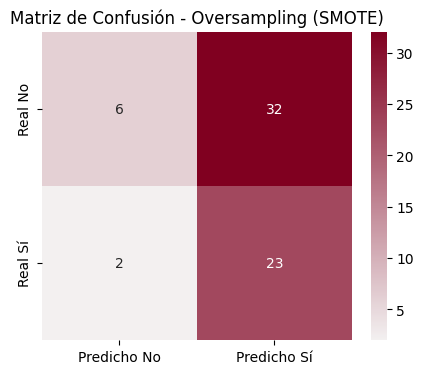

In [48]:
#Heatmap de la matriz de confusión del modelo con oversampling
matriz_over = confusion_matrix(y_test, y_pred_over_sampling)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(matriz_over, annot=True, fmt='d', cmap=sns.light_palette("#800020", as_cmap=True),
            xticklabels=['Predicho No', 'Predicho Sí'],
            yticklabels=['Real No', 'Real Sí'], ax=ax)
ax.set_title('Matriz de Confusión - Oversampling (SMOTE)')
plt.show()

# **Comparativa de tres modelos**

In [50]:
#Tabla comparativa de métricas de los modelos
etiqueta = True

tabla_metricas = pd.DataFrame({
    'Modelo': ['Sin balanceo', 'Oversampling'],
    'Exactitud': [accuracy_score(y_test, y_pred),
                  accuracy_score(y_test, y_pred_over_sampling)],
    'Precisión': [precision_score(y_test, y_pred, pos_label=etiqueta),
                  precision_score(y_test, y_pred_over_sampling, pos_label=etiqueta)],
    'Sensibilidad': [recall_score(y_test, y_pred, pos_label=etiqueta),
                     recall_score(y_test, y_pred_over_sampling, pos_label=etiqueta)]
}).round(3)

tabla_metricas

,Modelo,Exactitud,Precisión,Sensibilidad
0,Sin balanceo,0.698,0.800,0.32
1,Oversampling,0.460,0.418,0.92
